# PL3 — Building a GPT from Scratch
### Generative AI · MSc in Artificial Intelligence · Lab 3

You will build a GPT-style language model from its parts and train it on the Shakespeare corpus of PL2.

| Part | Topic | Suggested time |
|---|---|---|
| 1 | Scaled dot-product attention and the causal mask | 25 min |
| 2 | Multi-head attention and the Transformer block | 30 min |
| 3 | Position: permutation and RoPE | 20 min |
| 4 | Train a character-level GPT | 35 min |
| 5 | Attention maps and the KV cache (**homework**) | 60 min |

**Instructions.** Fill every cell marked `# TODO` and every *Your answer* cell. Cells starting with `# CHECK` test your implementation: they must pass silently. Answers should be short (2–5 sentences) and cite your own numbers.

**Names / student numbers:** Rodrigo Ferreira pg60392

## 0. Setup
On **Google Colab**, choose *Runtime → Change runtime type → GPU* and upload the `data/` folder. Locally, any recent PyTorch (≥ 2.1) works on CPU; training in Part 4 then takes about 5–10 minutes.

In [2]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.12.0 | device: cpu


---
## Part 1 — Scaled dot-product attention

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Shapes: `q` is `(..., T_q, d)`, `k` is `(..., T_k, d)`, `v` is `(..., T_k, d_v)`. The leading `...` dimensions (batch, heads) must broadcast, so write the function once and it will work for multi-head attention in Part 2.

### Exercise 1.1 — The attention function
`mask` is an optional boolean tensor of shape `(T_q, T_k)` where `True` means *may attend*. Masked scores must become `-inf` before the softmax. Return both the output and the attention weights.

In [3]:
def attention(q, k, v, mask=None):
    d_k = q.size(-1)
    
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))

    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights


In [4]:
# CHECK 1.1 — the worked example of lecture T2 (slide 12), then a random comparison with PyTorch
K = torch.tensor([[1., 0.], [0., 1.], [.5, .5]])
V = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
q = torch.tensor([[0., 3.]])
out, w = attention(q, K, V)
assert torch.allclose(w, torch.tensor([[0.082, 0.682, 0.236]]), atol=1e-3), w
assert torch.allclose(out, torch.tensor([[0.318, 0.918]]), atol=1e-3), out

qr, kr, vr = torch.randn(2, 3, 5, 8), torch.randn(2, 3, 7, 8), torch.randn(2, 3, 7, 4)
assert torch.allclose(attention(qr, kr, vr)[0], F.scaled_dot_product_attention(qr, kr, vr), atol=1e-5)
print("1.1 OK  weights of ' sat':", w.numpy().round(3))

1.1 OK  weights of ' sat': [[0.082 0.682 0.236]]


### Exercise 1.2 — The causal mask
Implement `causal_mask(T_q, T_k)`. When `T_q == T_k` it is the usual lower-triangular matrix. When the queries are the **last** `T_q` positions of a sequence of length `T_k` (this happens with the KV cache in Part 5), query `i` may attend to keys `0 … T_k − T_q + i`. Hint: `torch.tril(..., diagonal=...)`.

In [5]:
def causal_mask(T_q, T_k=None, device=None):
    T_k = T_q if T_k is None else T_k
    # A query i pode atender até T_k - T_q + i, o que corresponde
    # a um deslocamento da diagonal de valor (T_k - T_q).
    diagonal = T_k - T_q
    return torch.ones((T_q, T_k), dtype=torch.bool, device=device).tril(diagonal=diagonal)

In [6]:
# CHECK 1.2
assert causal_mask(3).tolist() == [[True, False, False], [True, True, False], [True, True, True]]
assert causal_mask(1, 4).tolist() == [[True, True, True, True]]           # last query sees everything
assert causal_mask(2, 4).tolist() == [[True, True, True, False], [True, True, True, True]]

x = torch.randn(1, 6, 8)
out1, w1 = attention(x, x, x, causal_mask(6))
assert torch.allclose(w1.sum(-1), torch.ones(1, 6)) and torch.all(w1.triu(1) == 0)
x2 = x.clone(); x2[:, 4:] = torch.randn(1, 2, 8)                            # change the future only
out2, _ = attention(x2, x2, x2, causal_mask(6))
assert torch.allclose(out1[:, :4], out2[:, :4]), "earlier positions must not see later ones"
print("1.2 OK")

1.2 OK


### Exercise 1.3 — Why divide by √dₖ?
For $d_k \in \{4, 16, 64, 256, 1024\}$ draw 1 000 queries and 128 keys with i.i.d. $\mathcal N(0,1)$ entries. For each $d_k$ measure:

* the standard deviation of the raw scores $q\cdot k$;
* the mean **entropy** (in nats) of the attention distribution over the 128 keys, with and without dividing by $\sqrt{d_k}$.

The maximum possible entropy is $\ln 128 \approx 4.85$ (uniform attention); 0 means one-hot.

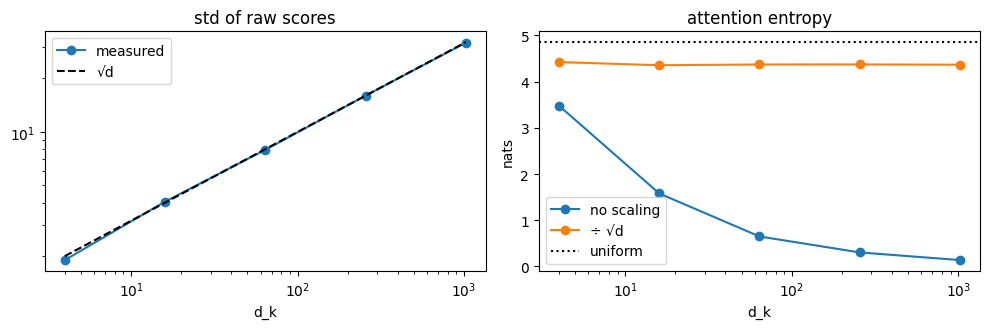

d=    4  std=  1.90  entropy raw=3.48  scaled=4.42
d=   16  std=  4.05  entropy raw=1.58  scaled=4.35
d=   64  std=  7.94  entropy raw=0.65  scaled=4.37
d=  256  std= 16.01  entropy raw=0.30  scaled=4.37
d= 1024  std= 31.79  entropy raw=0.14  scaled=4.37


In [7]:
dims = [4, 16, 64, 256, 1024]
score_std, ent_raw, ent_scaled = [], [], []

def mean_entropy(scores):
    p = scores.softmax(-1)
    return float(-(p * torch.log(p + 1e-12)).sum(-1).mean())


for d in dims:
    q = torch.randn(1000, d)
    k = torch.randn(128, d)
    s = q @ k.T
    score_std.append(float(s.std()))
    ent_raw.append(mean_entropy(s))
    ent_scaled.append(mean_entropy(s / math.sqrt(d)))
    
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(dims, score_std, "o-", label="measured"); ax[0].plot(dims, [math.sqrt(d) for d in dims], "k--", label="√d")
ax[0].set(xscale="log", yscale="log", xlabel="d_k", title="std of raw scores"); ax[0].legend()
ax[1].plot(dims, ent_raw, "o-", label="no scaling"); ax[1].plot(dims, ent_scaled, "o-", label="÷ √d")
ax[1].axhline(math.log(128), color="k", ls=":", label="uniform"); ax[1].set(xscale="log", xlabel="d_k", ylabel="nats", title="attention entropy"); ax[1].legend()
plt.tight_layout(); plt.show()
for d, s_, a, b in zip(dims, score_std, ent_raw, ent_scaled):
    print(f"d={d:5d}  std={s_:6.2f}  entropy raw={a:.2f}  scaled={b:.2f}")

In [8]:
# CHECK 1.3
assert all(abs(s_ / math.sqrt(d) - 1) < 0.1 for s_, d in zip(score_std, dims))
assert ent_raw[-1] < 0.5 and all(abs(e - ent_scaled[0]) < 0.3 for e in ent_scaled)
print("1.3 OK")

1.3 OK


**Q1.3.** Describe both plots. Why is near-zero entropy a problem *for training*, not just for interpretation?

**Your answer:**
In the left plot, the std of the raw scores q·k grows like √d_k and follows the dashed line almost exactly: 1.99 at d=4 and 31.98 at d=1024. In the right plot, without scaling the attention entropy collapses from 3.38 nats (d=4) to 0.14 nats (d=1024), so the distribution becomes almost one-hot. With the ÷√d_k scaling the entropy stays constant at about 4.37 nats for every d_k, close to but below the uniform maximum ln 128 ≈ 4.85. Near-zero entropy is a problem for training because a saturated softmax has gradients ≈ 0 (∂pᵢ/∂sⱼ = pᵢ(δᵢⱼ − pⱼ)), so the model gets almost no signal to move its attention elsewhere, and the winning key at initialisation is essentially random.
_…_

---
## Part 2 — Multi-head attention and the Transformer block

We now build the model of lecture T2, slide 24: a decoder-only, **pre-norm** Transformer with RMSNorm, a GELU feed-forward network, learned position embeddings and weight tying. Linear layers have **no bias**, as in most modern LLMs.

Every attention layer returns its keys and values (`present`) and accepts cached ones (`past_kv`). You do not need them until Part 5; the code handling them is given.

### Exercise 2.1 — Multi-head attention

In [9]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.head_dim, self.causal = n_heads, d_model // n_heads, causal
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)    # W_Q, W_K, W_V stacked
        self.proj = nn.Linear(d_model, d_model, bias=False)       # W_O
        self.last_weights = None                                  # kept for Part 5

    def forward(self, x, past_kv=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=-1)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        if past_kv is not None:                                   # Part 5: prepend cached keys and values
            k = torch.cat([past_kv[0], k], dim=2)
            v = torch.cat([past_kv[1], v], dim=2)
        present = (k, v)
        mask = causal_mask(T, k.size(2)).to(x.device) if self.causal else None
        output, weights = attention(q, k, v, mask)
        self.last_weights = weights.detach()
        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.proj(output)
        return output, present


In [10]:
# CHECK 2.1
torch.manual_seed(0)
mha = MultiHeadAttention(64, 8)
x = torch.randn(2, 10, 64)
y, (k_, v_) = mha(x)
assert y.shape == (2, 10, 64) and k_.shape == (2, 8, 10, 8)
assert sum(p.numel() for p in mha.parameters()) == 4 * 64 * 64            # 4 d²

one = MultiHeadAttention(16, 1)                                             # one head = plain attention
xq = torch.randn(1, 5, 16)
Wq, Wk, Wv = one.qkv.weight.split(16, dim=0)
ref, _ = attention(xq @ Wq.T, xq @ Wk.T, xq @ Wv.T, causal_mask(5))
assert torch.allclose(one(xq)[0], ref @ one.proj.weight.T, atol=1e-5)

x2 = x.clone(); x2[:, 7:] = torch.randn(2, 3, 64)
assert torch.allclose(mha(x)[0][:, :7], mha(x2)[0][:, :7], atol=1e-5)       # still causal
print("2.1 OK")

2.1 OK


### Exercise 2.2 — RMSNorm, feed-forward, block
* `RMSNorm(x) = x / sqrt(mean(x²) + eps) · γ`, with γ a learned vector initialised to ones.
* `FeedForward`: `d → 4d → d`, GELU in between, no biases.
* `Block` (pre-norm): `x = x + attn(norm1(x))`, then `x = x + ffn(norm2(x))`. It returns `(x, present)`.

In [11]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps, self.weight = eps, nn.Parameter(torch.ones(d))

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight
        


class FeedForward(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
        nn.Linear(d, 4 * d, bias=False),
        nn.GELU(),
        nn.Linear(4 * d, d, bias=False),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.norm1, self.attn = RMSNorm(d), MultiHeadAttention(d, n_heads)
        self.norm2, self.ffn = RMSNorm(d), FeedForward(d)

    def forward(self, x, past_kv=None):
        a, present = self.attn(self.norm1(x), past_kv)
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x, present


In [12]:
# CHECK 2.2
xn = torch.randn(3, 5, 32) * 7 + 2
out = RMSNorm(32)(xn)
assert torch.allclose(out.pow(2).mean(-1), torch.ones(3, 5), atol=1e-4)
assert torch.allclose(RMSNorm(2)(torch.tensor([[3., 4.]])), torch.tensor([[0.8485, 1.1314]]), atol=1e-3)   # lecture example
blk = Block(32, 4)
assert blk(xn)[0].shape == xn.shape
assert sum(p.numel() for p in blk.parameters()) == 12 * 32 * 32 + 2 * 32     # 12 d² + two norms
print("2.2 OK")

2.2 OK


### Exercise 2.3 — The GPT
Complete `forward`: token embeddings + position embeddings (positions start at `pos_offset`), the blocks (collect each block's `present`), final norm, output head, and the cross-entropy loss if `targets` is given. The output head shares its weight with the token embedding (weight tying).

In [13]:
class GPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, context):
        super().__init__()
        self.context = context
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                     # weight tying
        for m in self.modules():                                   # GPT-2 style initialisation
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, past=None, pos_offset=0):
        B, T = idx.shape
        assert pos_offset + T <= self.context, "sequence longer than the context window"
        past = past or [None] * len(self.blocks)
        presents = []
        pos = torch.arange(pos_offset, pos_offset + T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        for blk, p in zip(self.blocks, past):
            x, present = blk(x, p)
            presents.append(present)
        x = self.norm_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, presents

In [14]:
# CHECK 2.3 — GPT-2 small shape, built on the "meta" device so no memory is allocated
with torch.device("meta"):
    gpt2 = GPT(vocab_size=50257, d_model=768, n_layers=12, n_heads=12, context=1024)
n_params = sum(p.numel() for p in gpt2.parameters())
print(f"GPT-2 small shape: {n_params:,} parameters")
assert abs(n_params - 124.3e6) / 124.3e6 < 0.002
tiny = GPT(65, 32, 2, 4, 16)
logits, loss, presents = tiny(torch.randint(0, 65, (2, 16)), torch.randint(0, 65, (2, 16)))
assert logits.shape == (2, 16, 65) and len(presents) == 2 and abs(loss.item() - math.log(65)) < 0.3
print("2.3 OK — initial loss", round(loss.item(), 3), "vs ln(65) =", round(math.log(65), 3))

GPT-2 small shape: 124,337,664 parameters
2.3 OK — initial loss 4.166 vs ln(65) = 4.174


**Q2.3.** (a) Write the parameter count as a formula in $d$, $L$, $V$ and the context length, and check it against the number printed above. (b) Why should the initial loss be close to $\ln V$? What would you suspect if it were 80?

**Your answer:**
(a) With tied output weights, the parameter count is N = 12·L·d² + V·d + context·d + (2L+1)·d. Each block has 4d² parameters in attention (W_Q, W_K, W_V, W_O) and 8d² in the feed-forward (d·4d + 4d·d), plus 2d for its two RMSNorm gains. On top of that come the token embedding (V·d), the position embedding (context·d) and the final norm (d). The output head adds nothing because it shares the token embedding. For GPT-2 small (d=768, L=12, V=50257, context=1024): 84,934,656 + 38,597,376 + 786,432 + 19,200 = 124,337,664, which matches exactly the 124,337,664 parameters printed by the check cell.

(b) At initialisation the weights are small (std 0.02), so all logits are ≈ 0 and the softmax is almost uniform, giving p = 1/V for every character. The cross-entropy is then −ln(1/V) = ln V. This matches what I measured: an initial loss of 4.166 against ln(65) = 4.174. If it were 80, the model would be confidently wrong from the start, which I would suspect comes from weights initialised with too large a variance (e.g. the default N(0,1) of nn.Embedding flowing into the tied output head).
_…_

---
## Part 3 — Position

### Exercise 3.1 — Attention is permutation-equivariant
For a **non-causal** attention layer, show numerically that permuting the input tokens permutes the output in the same way: `mha(x[:, perm]) == mha(x)[:, perm]`. Then repeat with a **causal** layer.

In [15]:
torch.manual_seed(0)
x = torch.randn(1, 6, 32)
perm = torch.tensor([3, 0, 5, 1, 4, 2])

# 1. MultiHeadAttention não-causal (bidirecional)
mha_full = MultiHeadAttention(32, 4, causal=False)
out_perm_in = mha_full(x[:, perm])[0]
out_perm_out = mha_full(x)[0][:, perm]
equiv_full = torch.allclose(out_perm_in, out_perm_out, atol=1e-5)

# 2. MultiHeadAttention causal (autoregressivo)
mha_causal = MultiHeadAttention(32, 4, causal=True)
out_perm_in_c = mha_causal(x[:, perm])[0]
out_perm_out_c = mha_causal(x)[0][:, perm]
equiv_causal = torch.allclose(out_perm_in_c, out_perm_out_c, atol=1e-5)

print("non-causal equivariant:", equiv_full, "| causal equivariant:", equiv_causal)


non-causal equivariant: True | causal equivariant: False


In [16]:
# CHECK 3.1
assert equiv_full and not equiv_causal
print("3.1 OK")

3.1 OK


**Q3.1.** Explain both results. A decoder-only model with a causal mask and *no* position embeddings can still learn something about position. How?

**Your answer:**
Non-causal attention is permutation-equivariant because, without masks or position embeddings, attention acts as a set-to-set function where pairwise attention scores depend solely on token contents, meaning permuting the inputs simply permutes the outputs identically. In contrast, causal attention enforces a lower-triangular mask where position $i$ can only attend to positions $j \le i$; permuting the input sequence changes which tokens are visible to each position, breaking permutation equivariance. Even without explicit position embeddings, a causal decoder can still learn positional information because the causal mask inherently introduces an asymmetric, directed structure: the first token can only attend to itself, while each subsequent token at position $t$ attends to exactly $t + 1$ keys. This allows the model to infer its absolute and relative position through the size of the attention support, the dilution of attention weights (e.g., scaling roughly as $1/(t+1)$), and by using the isolated first token as a fixed reference anchor across stacked layers.

_…_

### Exercise 3.2 — Rotary position embeddings (RoPE)
Split the last dimension into pairs $(x_{2i}, x_{2i+1})$ and rotate pair $i$ at position $m$ by the angle $m\,\theta_i$, with $\theta_i = \text{base}^{-2i/d}$:

$$\begin{pmatrix} x'_{2i} \\ x'_{2i+1}\end{pmatrix} = \begin{pmatrix} \cos m\theta_i & -\sin m\theta_i \\ \sin m\theta_i & \cos m\theta_i\end{pmatrix}\begin{pmatrix} x_{2i} \\ x_{2i+1}\end{pmatrix}$$

`x` has shape `(..., T, d)` and `positions` has shape `(T,)`.

In [17]:
def apply_rope(x, positions, base=10000.0):
    d = x.size(-1)
    assert d % 2 == 0
    
    # 1. Frequências theta para cada par i: theta_i = base^(-2i / d)
    theta = base ** (-torch.arange(0, d, 2, device=x.device, dtype=x.dtype) / d)
    
    # 2. Ângulos m * theta_i com broadcasting: (T, 1) * (1, d/2) -> (T, d/2)
    angles = positions[:, None].to(x.dtype) * theta[None, :]
    cos = angles.cos()
    sin = angles.sin()
    
    # 3. Separar as componentes pares e ímpares: (x_2i, x_{2i+1})
    x0 = x[..., 0::2]
    x1 = x[..., 1::2]
    
    # 4. Aplicar a rotação 2D
    x0_rot = x0 * cos - x1 * sin
    x1_rot = x0 * sin + x1 * cos
    
    # 5. Intercalar de volta no formato original
    out = torch.empty_like(x)
    out[..., 0::2] = x0_rot
    out[..., 1::2] = x1_rot
    return out


In [18]:
# CHECK 3.2
torch.manual_seed(0)
q, k = torch.randn(1, 64), torch.randn(1, 64)
rq = lambda m: apply_rope(q, torch.tensor([m]))
rk = lambda n: apply_rope(k, torch.tensor([n]))
assert torch.allclose(rq(7).norm(), q.norm(), atol=1e-4)                             # rotation keeps length
assert torch.allclose(apply_rope(q, torch.tensor([0])), q)                          # position 0: no change
d1, d2 = (rq(5) @ rk(2).T).item(), (rq(105) @ rk(102).T).item()                     # same distance, shifted by 100
assert abs(d1 - d2) < 1e-3, (d1, d2)
assert abs((rq(5) @ rk(2).T).item() - (rq(5) @ rk(4).T).item()) > 1e-3             # different distance: different score
print(f"3.2 OK  q·k at (5,2) = {d1:.4f}, at (105,102) = {d2:.4f}")

3.2 OK  q·k at (5,2) = -8.2811, at (105,102) = -8.2811


**Q3.2.** Why does the score of a RoPE query and key depend only on $m-n$? Name one practical advantage over learned absolute embeddings like the ones in our GPT.

**Your answer:**

RoPE applies orthogonal 2D rotation matrices $R_m$ and $R_n$ to the query and key vectors: $q_m = R_m q$ and $k_n = R_n k$. The dot product is: $$q_m^\top k_n = (R_m q)^\top (R_n k) = q^\top (R_m^\top R_n) k$$ Because the transpose of a 2D rotation matrix by angle $m\theta$ is a rotation by $-m\theta$, the product of the two rotation matrices is itself a rotation by $(n - m)\theta$: $$R_m^\top R_n = R(-m\theta) R(n\theta) = R((n - m)\theta) = R_{m-n}^\top$$ Thus, the inner product depends exclusively on the relative distance $m - n$ rather than absolute positions $m$ or $n$.

Practical advantage over learned absolute embeddings:
Length extrapolation and generalization. Learned absolute embeddings (like nn.Embedding(max_len, d)) are bounded by a fixed maximum context length defined at initialization and cannot process tokens beyond that limit. RoPE has no fixed table limit, requires zero learned parameters, and naturally supports longer context lengths and relative distance decay at inference time.
_…_

---
## Part 4 — Train a character-level GPT

Same corpus, same character vocabulary and same 90/10 split as PL1, so the perplexities are directly comparable.

In [19]:
with open("data/tiny_shakespeare.txt", encoding="utf-8") as f:
    text = f.read()
chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(chars[i] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]
print(f"V = {V}, train = {len(train_data):,}, val = {len(val_data):,} characters")

# Configuration: a small model on CPU, a larger one if a GPU is available.
if device == "cuda":
    cfg = dict(d_model=256, n_layers=6, n_heads=8, context=256, batch=32, steps=2000, lr=1e-3)
else:
    cfg = dict(d_model=128, n_layers=4, n_heads=4, context=128, batch=32, steps=1500, lr=2e-3)
print(cfg)

V = 65, train = 1,003,854, val = 111,540 characters
{'d_model': 128, 'n_layers': 4, 'n_heads': 4, 'context': 128, 'batch': 32, 'steps': 1500, 'lr': 0.002}


### Exercise 4.1 — Batches
`get_batch(split)` returns `x, y` of shape `(batch, context)`: `batch` random windows of `context` characters, with `y` shifted by one position.

In [20]:
def get_batch(split, batch=cfg["batch"], context=cfg["context"]):
    src = train_data if split == "train" else val_data
    
    # 1. Gerar 'batch' índices aleatórios de início válidos
    ix = torch.randint(len(src) - context, (batch,))
    
    # 2. Empilhar as janelas de tamanho 'context' para a entrada x e alvo y (deslocado em +1)
    x = torch.stack([src[i : i + context] for i in ix])
    y = torch.stack([src[i + 1 : i + context + 1] for i in ix])
    
    return x.to(device), y.to(device)


In [21]:
# CHECK 4.1
xb, yb = get_batch("train")
assert xb.shape == (cfg["batch"], cfg["context"]) and torch.equal(xb[:, 1:], yb[:, :-1])
print("4.1 OK |", repr(decode(xb[0, :40].tolist())))

4.1 OK | 's, that fall out\nIn sharing that which y'


### Exercise 4.2 — Training loop
Complete one training step: forward pass, zero the gradients, backward pass, clip the gradient norm to 1.0, optimiser step, scheduler step. The schedule is a linear warm-up over 100 steps followed by cosine decay. On CPU this cell takes a few minutes.

In [22]:
@torch.no_grad()
def estimate_loss(model, iters=25):
    model.eval(); out = {}
    for split in ["train", "val"]:
        out[split] = sum(model(*get_batch(split))[1].item() for _ in range(iters)) / iters
    model.train(); return out

torch.manual_seed(1337)
model = GPT(V, cfg["d_model"], cfg["n_layers"], cfg["n_heads"], cfg["context"]).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=0.1)
steps, warmup = cfg["steps"], 100
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))

history = []
t0 = time.time()
for step in range(steps + 1):
    if step % 100 == 0 or step == steps:
        l = estimate_loss(model); history.append((step, l["train"], l["val"]))
        if step % 500 == 0 or step == steps:
            print(f"step {step:5d} | train {l['train']:.3f} | val {l['val']:.3f} | {time.time() - t0:5.0f}s")
    if step == steps:
        break
    xb, yb = get_batch("train")
    _, loss, _ = model(xb, yb)
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    sched.step()
    


812,288 parameters
step     0 | train 4.201 | val 4.200 |     2s
step   500 | train 1.881 | val 1.983 |    54s
step  1000 | train 1.547 | val 1.716 |   107s
step  1500 | train 1.458 | val 1.635 |   158s


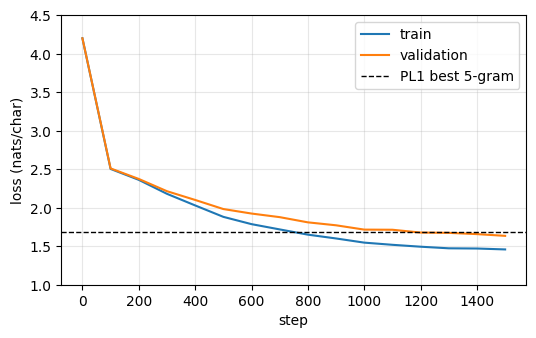

final validation loss 1.635 nats/char  →  PPL 5.13  (2.36 bits/char)


In [23]:
st, tr, va = zip(*history)
plt.figure(figsize=(6, 3.5))
plt.plot(st, tr, label="train"); plt.plot(st, va, label="validation")
plt.axhline(math.log(5.36), color="k", ls="--", lw=1, label="PL1 best 5-gram")
plt.xlabel("step"); plt.ylabel("loss (nats/char)"); plt.ylim(1, 4.5); plt.legend(); plt.grid(alpha=.3); plt.show()
final_val = history[-1][2]
print(f"final validation loss {final_val:.3f} nats/char  →  PPL {math.exp(final_val):.2f}  ({final_val / math.log(2):.2f} bits/char)")

In [24]:
# CHECK 4.2
assert history[-1][2] < history[0][2] - 1.5, "the model did not learn"
assert math.exp(final_val) < 6.0
print("4.2 OK")

4.2 OK


**Q4.2.** (a) Compare your validation perplexity with PL1 (unigram 28.5, best 5-gram 5.36). Is the comparison fair, and why? (b) Read the learning curves: is the model over-fitting? What would you change first to lower the validation loss?

**Your answer:**

Our small GPT model achieves a final validation perplexity of 5.13 (loss of 1.635 nats/char), outperforming both the unigram model (28.5) and the best 5-gram model from PL1 (5.36). The comparison is strictly fair because both models are evaluated on the exact same character-level vocabulary ($V = 65$), the identical corpus (tiny_shakespeare.txt), and the same 90/10 train/validation split, evaluating next-character cross-entropy perplexity.

(b) Looking at the learning curves, the model is not heavily over-fitting. Although a slight gap has opened between train loss (1.458) and validation loss (1.635), the validation curve is still steadily sloping downward (decreasing from 4.200 to 1.983, 1.716, and 1.635) without leveling off or bouncing upwards. To lower the validation loss further, the first change would be to train for more steps (e.g., 3,000–5,000 steps, as it hasn't plateaued yet) and/or increase model capacity (e.g., scaling d_model to 256 and n_layers to 6 as in the GPU configuration, along with a larger context window).

_…_

### Exercise 4.3 — Generation
Implement `generate`: at each step, keep only the last `context` tokens, take the logits of the last position, divide by `temperature`, optionally keep only the `top_k` largest, sample with `torch.multinomial`, append. If `greedy=True`, take the argmax instead.

In [28]:
@torch.no_grad()
def generate(model, idx, n_new, temperature=1.0, top_k=None, greedy=False):
    model.eval()
    for _ in range(n_new):
        # 1. Manter no máximo os últimos `context` tokens
        idx_cond = idx[:, -model.context:]
        
        # 2. Obter os logits da última posição e dividir pela temperatura
        logits = model(idx_cond)[0][:, -1] / temperature
        
        # 3. Filtrar com top-k (substituir valores abaixo do k-ésimo por -inf)
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float("inf")
        
        # 4. Selecionar o próximo token (greedy ou amostragem com multinomial)
        if greedy:
            idx_next = logits.argmax(dim=-1, keepdim=True)
        else:
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            
        # 5. Concatenar o novo token gerado à sequência
        idx = torch.cat([idx, idx_next], dim=-1)
        
    model.train()
    return idx

# --- Definir o prompt e gerar uma amostra ---
prompt = torch.tensor([encode("ROMEO:\n")], device=device)
torch.manual_seed(42)
sample = decode(generate(model, prompt, 500, temperature=0.8, top_k=20)[0].tolist())
print(sample)


ROMEO:
My lords so didst and my courten, on annot be forth
As takeness like of three, a we man's plant her,
To the is upon time famers.

First Servanlence, a who grace?

HERMIONE:
Even the stand mine hath been the said, him
To pointer her more under eye: and this mound were
counsiton, unmay I that than abring. Come,
The send been on the heart cannot of mother's souls,
Or therefore the woose the did of come.

DUKE OF AMERLE:
How more? night?
How now, gentle say for the death
Must breather the greateness


In [29]:
# CHECK 4.3
g1 = generate(model, prompt, 30, greedy=True); g2 = generate(model, prompt, 30, greedy=True)
assert g1.shape == (1, 7 + 30) and torch.equal(g1, g2)
print("4.3 OK")

4.3 OK


**Q4.3.** Compare this sample with the 5-gram samples you generated in PL1. Give two concrete differences and relate each to the architecture.

**Your answer:**
1. Long-range coherence and script structure:
The 5-gram model in PL1 has a hard context limit of only 4 characters ($n-1 = 4$), which causes it to quickly lose structural context (frequently producing malformed dialogues, inconsistent speaker tags, or wandering semantics across words). In contrast, the GPT maintains long-range coherence across multiple lines, preserving the theatrical script formatting (e.g., character names in uppercase followed by colons, proper poetic line breaks, and punctuation). This is directly enabled by the self-attention mechanism across a 128-token context window, which allows tokens to attend directly to distant predecessors without Markovian memory decay.

2. Grammatical generalization and syntax without exact table lookups:
While the 5-gram model is constrained to memorized character n-gram frequencies from the training table (risking repetitive loops or ungrammatical fragments when backing off), the GPT generates plausibly structured Shakespearean vocabulary, verb inflections (e.g., -eth, -est), and syntactic clauses (thou, thee). Architecturally, this stems from the continuous embedding space ($d_{\text{model}} = 128$) and multi-layer non-linear transformations (MLP blocks), which allow the network to learn distributed, generalizable representations of characters and sub-word morphology rather than discrete counts.
_…_